<a href="https://colab.research.google.com/github/MaheenZaheer/Bank_Management_System/blob/main/Night_Object_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [12]:
%pip install -q ultralytics


In [13]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("Model loaded successfully!")

Model loaded successfully!


In [14]:
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    imgsz=416,
    conf=0.25,
    save=True
)

print("Detection completed!")


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 416x320 4 persons, 1 bus, 7.6ms
Speed: 1.5ms preprocess, 7.6ms inference, 1.2ms postprocess per image at shape (1, 3, 416, 320)
Results saved to /content/runs/detect/predict-2
Detection completed!


In [15]:
from IPython.display import display

display(results[0].plot())

array([[[119, 146, 172],
        [121, 148, 174],
        [122, 152, 177],
        ...,
        [161, 171, 188],
        [160, 170, 187],
        [160, 170, 187]],

       [[120, 147, 173],
        [122, 149, 175],
        [123, 153, 178],
        ...,
        [161, 171, 188],
        [160, 170, 187],
        [160, 170, 187]],

       [[123, 150, 176],
        [124, 151, 177],
        [125, 155, 180],
        ...,
        [161, 171, 188],
        [160, 170, 187],
        [160, 170, 187]],

       ...,

       [[183, 182, 186],
        [179, 178, 182],
        [180, 179, 183],
        ...,
        [121, 111, 117],
        [113, 103, 109],
        [115, 105, 111]],

       [[165, 164, 168],
        [173, 172, 176],
        [187, 186, 190],
        ...,
        [102,  92,  98],
        [101,  91,  97],
        [103,  93,  99]],

       [[123, 122, 126],
        [145, 144, 148],
        [176, 175, 179],
        ...,
        [ 95,  85,  91],
        [ 96,  86,  92],
        [ 98,  88,  94]]

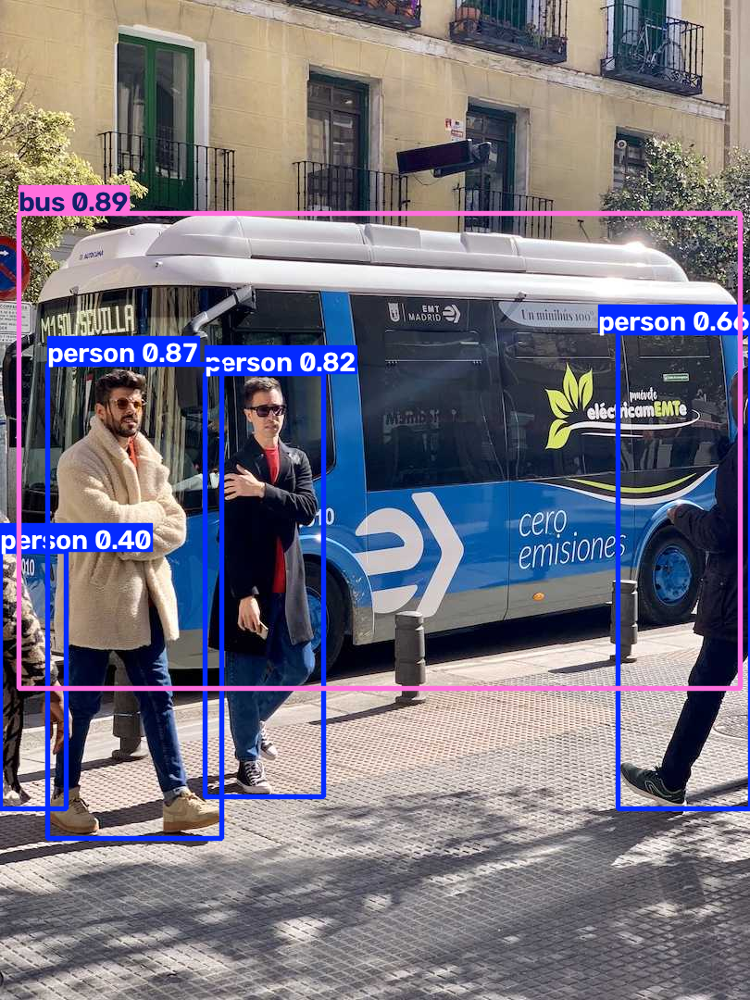

In [16]:
from PIL import Image
from IPython.display import display

annotated_image = results[0].plot()
annotated_image = annotated_image[:, :, ::-1]

display(Image.fromarray(annotated_image))

In [17]:
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence, 2)
    )

Object: bus | Confidence: 0.89
Object: person | Confidence: 0.87
Object: person | Confidence: 0.82
Object: person | Confidence: 0.66
Object: person | Confidence: 0.4


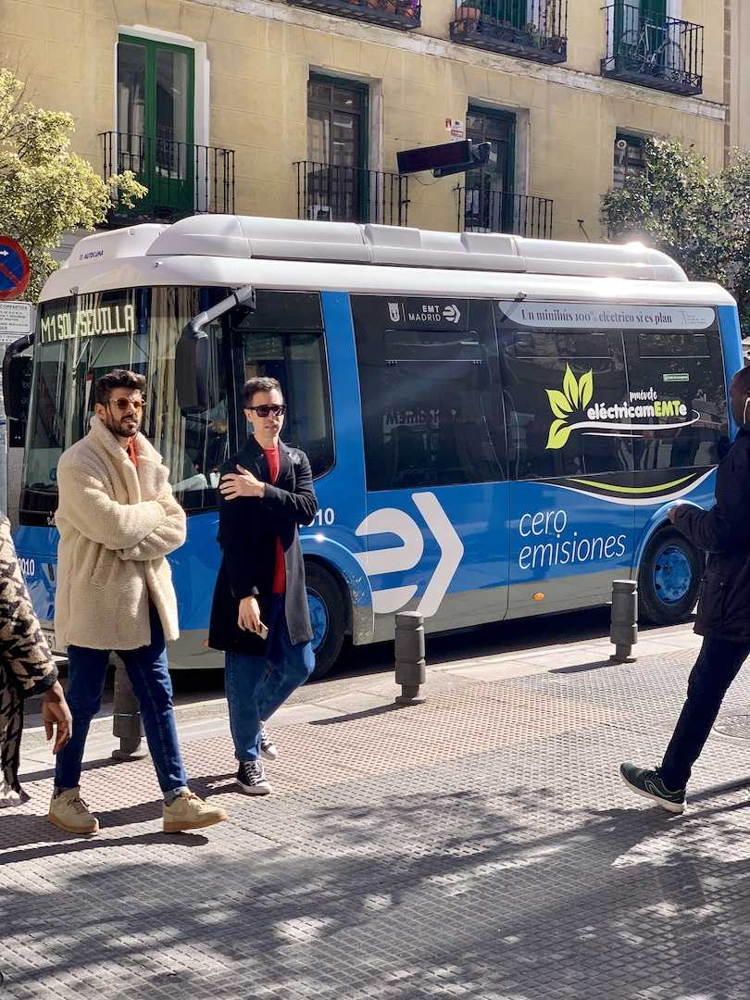

In [18]:
import requests
from PIL import Image
from io import BytesIO
from IPython.display import display

image_url = "https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/bus.jpg"

response = requests.get(image_url, timeout=30)
response.raise_for_status()

night_image = Image.open(BytesIO(response.content)).convert("RGB")

display(night_image)

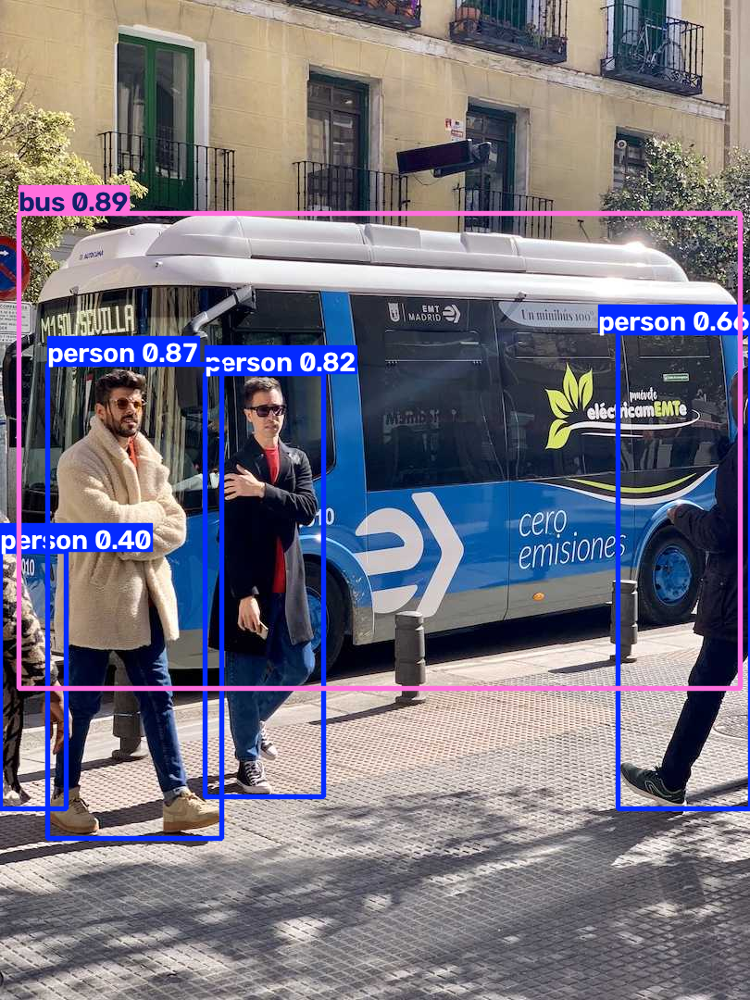

In [19]:
night_results = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.25,
    verbose=False
)

display(
    Image.fromarray(
        night_results[0].plot()[:, :, ::-1]
    )
)

In [20]:
for box in night_results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence, 3)
    )

Object: bus | Confidence: 0.888
Object: person | Confidence: 0.871
Object: person | Confidence: 0.824
Object: person | Confidence: 0.656
Object: person | Confidence: 0.395


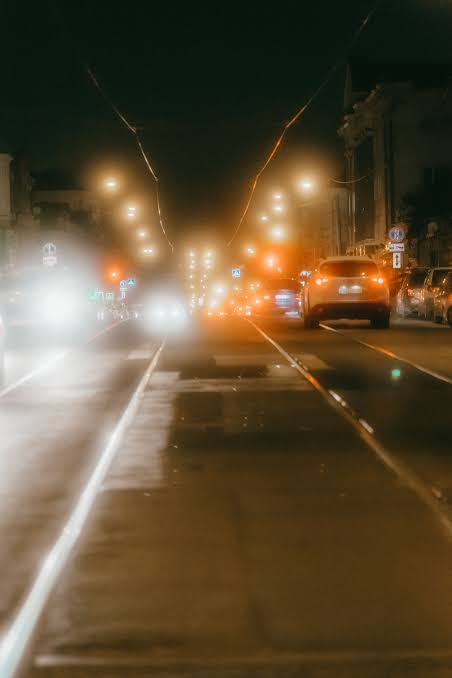

In [22]:
from PIL import Image
from IPython.display import display

image_path = "/content/images.jpg"

night_image = Image.open(image_path).convert("RGB")

display(night_image)

array([[[ 11,  24,  15],
        [ 11,  24,  15],
        [ 10,  23,  14],
        ...,
        [ 44,  41,  26],
        [ 46,  43,  28],
        [ 48,  45,  30]],

       [[ 11,  24,  15],
        [ 11,  24,  15],
        [ 10,  23,  14],
        ...,
        [ 44,  41,  26],
        [ 45,  42,  27],
        [ 46,  43,  28]],

       [[ 11,  24,  15],
        [ 11,  24,  15],
        [ 10,  23,  14],
        ...,
        [ 43,  40,  25],
        [ 43,  40,  25],
        [ 43,  40,  25]],

       ...,

       [[196, 218, 216],
        [195, 217, 215],
        [194, 214, 215],
        ...,
        [ 80,  54,  17],
        [ 80,  54,  17],
        [ 80,  54,  17]],

       [[195, 217, 215],
        [194, 216, 214],
        [193, 213, 214],
        ...,
        [ 79,  53,  18],
        [ 79,  53,  18],
        [ 79,  53,  18]],

       [[194, 216, 214],
        [193, 215, 213],
        [192, 212, 213],
        ...,
        [ 78,  52,  17],
        [ 78,  52,  17],
        [ 78,  52,  17]]], dtype=uint8)
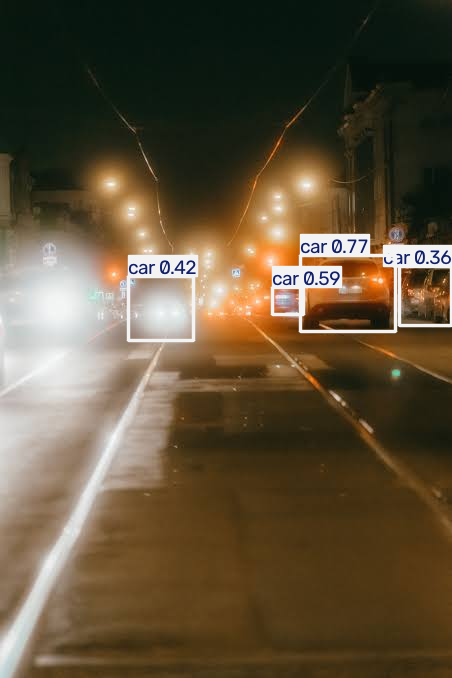

In [23]:
night_results = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.25,
    verbose=False
)

display(night_results[0].plot()[:, :, ::-1])

In [24]:
for box in night_results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence, 3)
    )

Object: car | Confidence: 0.775
Object: car | Confidence: 0.586
Object: car | Confidence: 0.417
Object: car | Confidence: 0.361


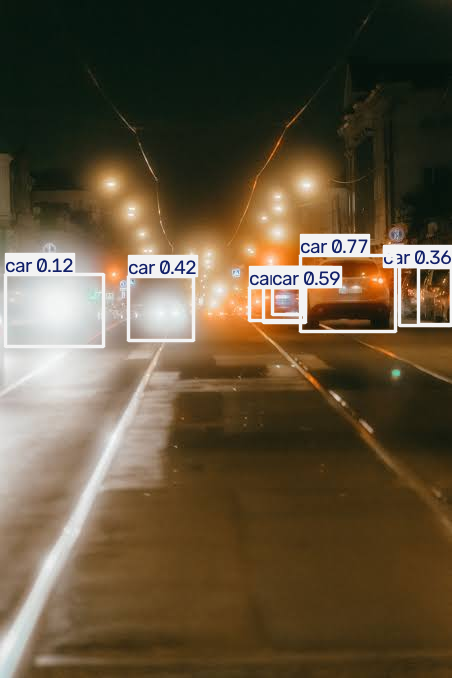

Object: car | Confidence: 0.775
Object: car | Confidence: 0.586
Object: car | Confidence: 0.417
Object: car | Confidence: 0.361
Object: car | Confidence: 0.179
Object: car | Confidence: 0.139
Object: car | Confidence: 0.125
Object: car | Confidence: 0.114


In [25]:
night_results_low = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.10,
    verbose=False
)

display(
    Image.fromarray(
        night_results_low[0].plot()[:, :, ::-1]
    )
)

for box in night_results_low[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence, 3)
    )

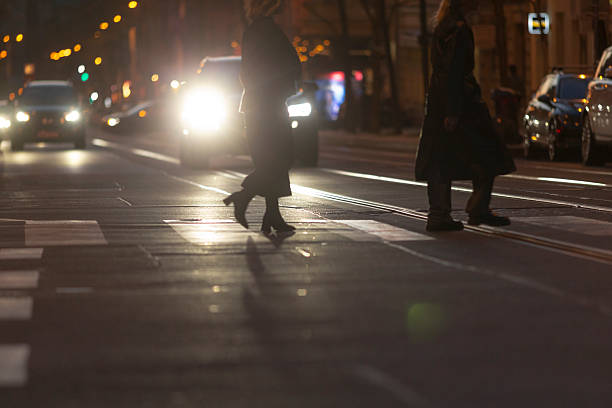

In [26]:
from PIL import Image
from IPython.display import display

image_path = "/content/istockphoto-2220597698-612x612.jpg"

night_image = Image.open(image_path).convert("RGB")

display(night_image)

array([[[ 47,  37,  28],
        [ 47,  37,  28],
        [ 46,  36,  27],
        ...,
        [ 89,  64,  23],
        [122, 101,  38],
        [127, 106,  25]],

       [[ 47,  37,  28],
        [ 47,  37,  28],
        [ 46,  36,  27],
        ...,
        [ 87,  65,  28],
        [122, 101,  44],
        [129, 110,  34]],

       [[ 47,  37,  28],
        [ 46,  36,  27],
        [ 45,  35,  26],
        ...,
        [ 79,  60,  30],
        [115,  97,  49],
        [129, 111,  47]],

       ...,

       [[ 47,  40,  34],
        [ 47,  40,  34],
        [ 47,  40,  34],
        ...,
        [ 49,  39,  38],
        [ 49,  39,  38],
        [ 48,  38,  37]],

       [[ 47,  40,  34],
        [ 47,  40,  34],
        [ 47,  40,  34],
        ...,
        [ 49,  39,  38],
        [ 49,  39,  38],
        [ 49,  39,  38]],

       [[ 47,  40,  34],
        [ 47,  40,  34],
        [ 47,  40,  34],
        ...,
        [ 49,  39,  38],
        [ 49,  39,  38],
        [ 50,  40,  39]]], dtype=uint8)
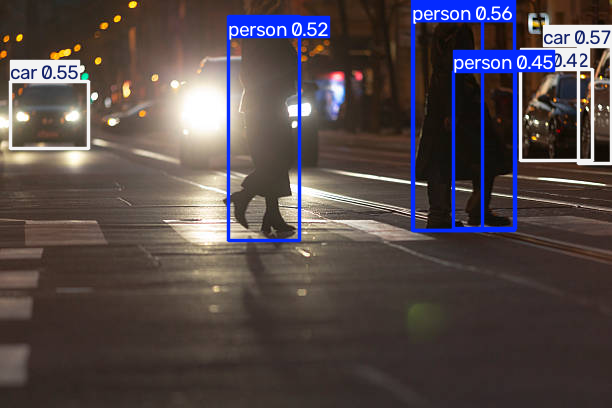

In [27]:
night_results = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.25,
    verbose=False
)

display(night_results[0].plot()[:, :, ::-1])

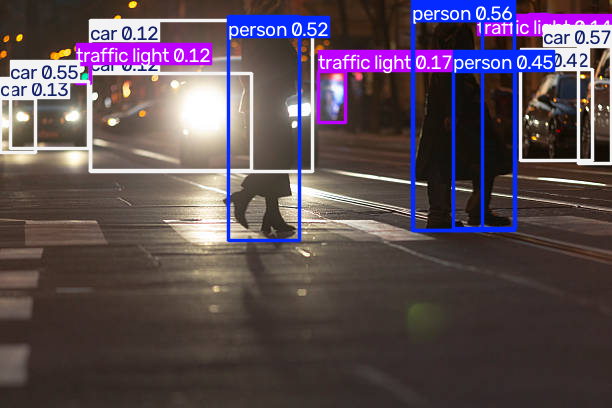

Object: car | Confidence: 0.572
Object: person | Confidence: 0.557
Object: car | Confidence: 0.552
Object: person | Confidence: 0.516
Object: person | Confidence: 0.454
Object: car | Confidence: 0.416
Object: person | Confidence: 0.252
Object: traffic light | Confidence: 0.17
Object: traffic light | Confidence: 0.145
Object: car | Confidence: 0.125
Object: traffic light | Confidence: 0.12
Object: car | Confidence: 0.119
Object: car | Confidence: 0.115


In [28]:
night_results_low = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.10,
    verbose=False
)

display(
    Image.fromarray(
        night_results_low[0].plot()[:, :, ::-1]
    )
)

for box in night_results_low[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence, 3)
    )

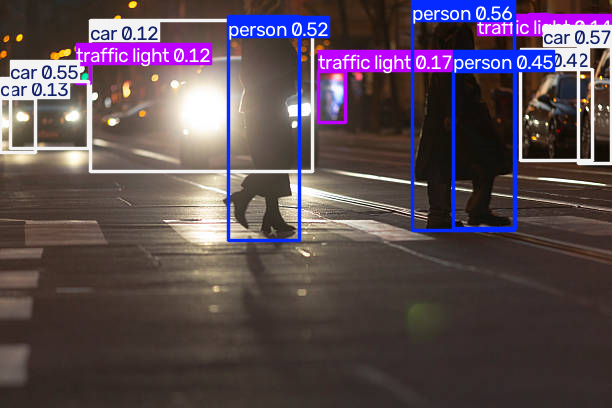

In [29]:
nms_results = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.10,
    iou=0.45,
    verbose=False
)

display(
    Image.fromarray(
        nms_results[0].plot()[:, :, ::-1]
    )
)

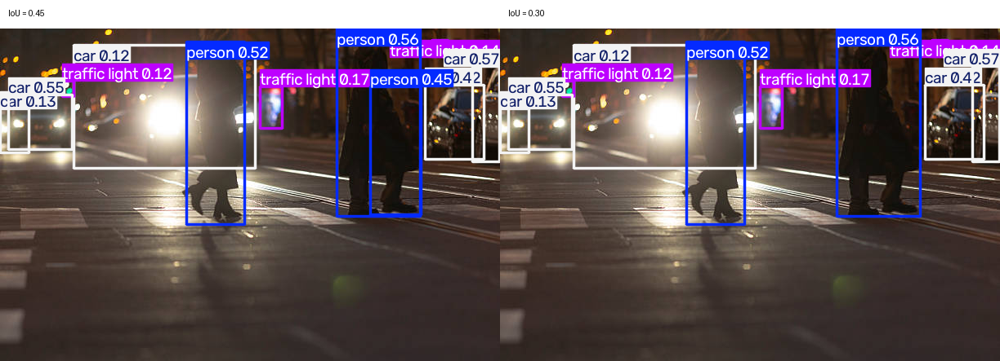


IoU 0.45: 11 total detections
car 0.572
person 0.557
car 0.552
person 0.516
person 0.454
car 0.416
traffic light 0.17
traffic light 0.145
car 0.125
traffic light 0.12
car 0.119

IoU 0.30: 10 total detections
car 0.572
person 0.557
car 0.552
person 0.516
car 0.416
traffic light 0.17
traffic light 0.145
car 0.125
traffic light 0.12
car 0.119


In [30]:

from PIL import Image, ImageDraw
from IPython.display import display

# Run A: current NMS setting
result_045 = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.10,
    iou=0.45,
    verbose=False
)[0]

# Run B: more aggressive NMS
result_030 = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.10,
    iou=0.30,
    verbose=False
)[0]

# Convert detection plots into displayable images
img_045 = Image.fromarray(result_045.plot()[:, :, ::-1])
img_030 = Image.fromarray(result_030.plot()[:, :, ::-1])

# Display both results side by side
img_045.save("/content/night_iou045.jpg")
img_030.save("/content/night_iou030.jpg")

comparison = Image.new(
    "RGB",
    (img_045.width * 2, img_045.height + 35),
    "white"
)

comparison.paste(img_045, (0, 35))
comparison.paste(img_030, (img_045.width, 35))

draw = ImageDraw.Draw(comparison)
draw.text((10, 10), "IoU = 0.45", fill="black")
draw.text((img_045.width + 10, 10), "IoU = 0.30", fill="black")

display(comparison)

# Print detection counts and confidence scores
for label, result in [
    ("IoU 0.45", result_045),
    ("IoU 0.30", result_030)
]:
    print(f"\n{label}: {len(result.boxes)} total detections")

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(
            model.names[class_id],
            round(confidence, 3)
        )



Confidence threshold: 0.1
Total detections: 10
car 0.572
person 0.557
car 0.552
person 0.516
car 0.416
traffic light 0.17
traffic light 0.145
car 0.125
traffic light 0.12
car 0.119


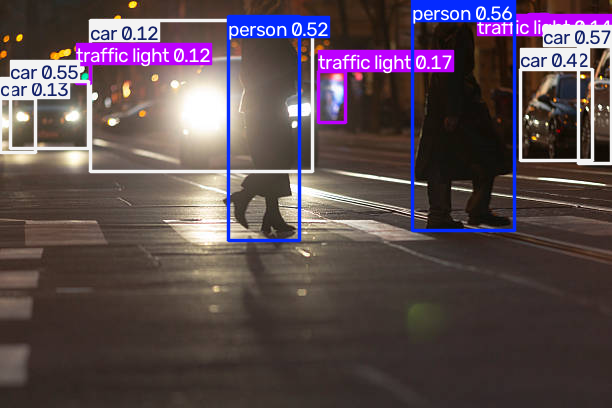


Confidence threshold: 0.25
Total detections: 5
car 0.572
person 0.557
car 0.552
person 0.516
car 0.416


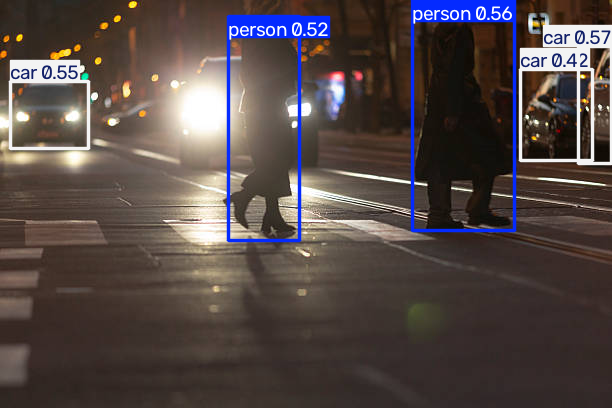


Confidence threshold: 0.35
Total detections: 5
car 0.572
person 0.557
car 0.552
person 0.516
car 0.416


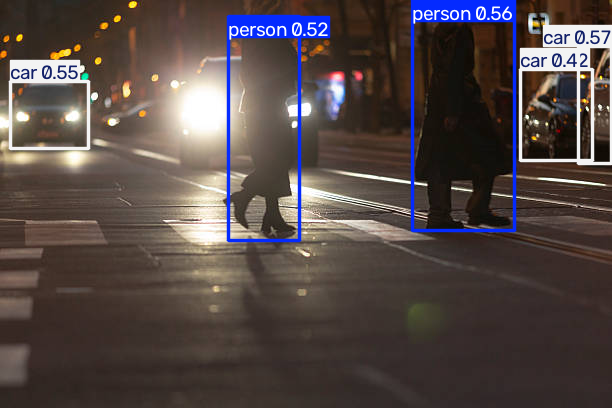

In [31]:

from IPython.display import display
from PIL import Image

thresholds = [0.10, 0.25, 0.35]

for threshold in thresholds:
    result = model.predict(
        source=night_image,
        imgsz=416,
        conf=threshold,
        iou=0.30,
        verbose=False
    )[0]

    print(f"\nConfidence threshold: {threshold}")
    print(f"Total detections: {len(result.boxes)}")

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print(
            model.names[class_id],
            round(confidence, 3)
        )

    display(
        Image.fromarray(result.plot()[:, :, ::-1])
    )


### Experiment 1: Confidence Threshold and NMS Analysis

**Objective:** Investigate YOLO11n's behaviour on a nighttime road image under different detection thresholds and NMS settings.

**Observations:**
- At confidence threshold 0.10 and IoU 0.45, the model produced 11 detections.
- Reducing the IoU threshold to 0.30 reduced the total detections to 10. One person detection with confidence 0.454 was removed.
- The three suspected traffic-light detections remained unchanged after the NMS adjustment.
- Increasing the confidence threshold reduced the total detections in the observed image, but the correctness of the removed detections must be verified.

**Interpretation:** The experiment suggests that NMS tuning can suppress some overlapping detections, while confidence thresholding changes which predictions are retained. Neither change has yet demonstrated an improvement in overall accuracy.

**Limitation:** These observations come from a single image. Precision, recall, and detection accuracy cannot be established without verified ground-truth annotations.

**Next experiment:** Apply Contrast Limited Adaptive Histogram Equalization (CLAHE) to the nighttime image and compare the enhanced and original images using the same model settings.


Original image


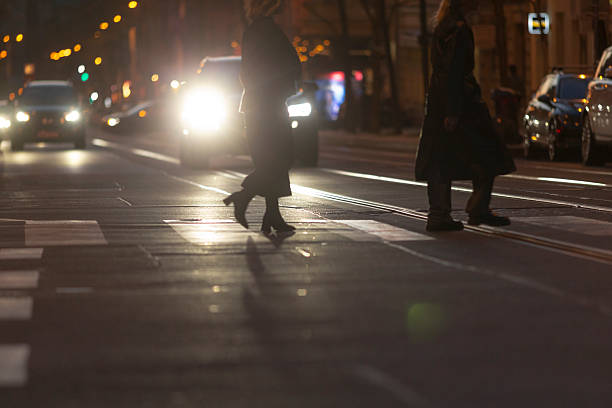

CLAHE-enhanced image


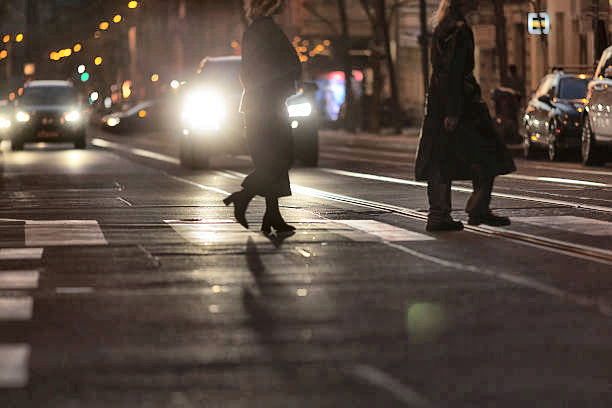

Original image detections


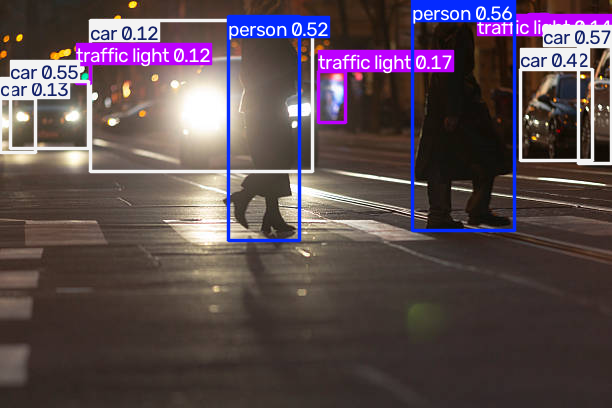

Enhanced image detections


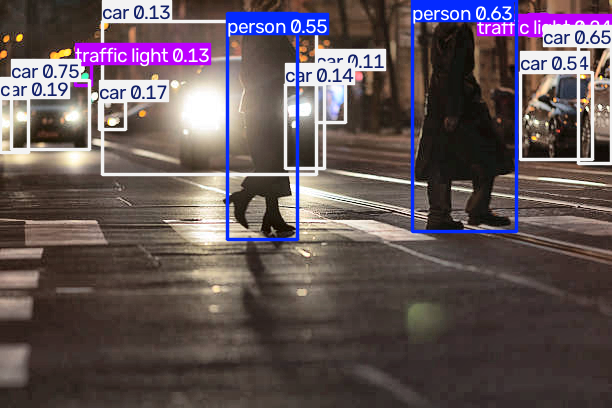


Original: 10 detections
car 0.572
person 0.557
car 0.552
person 0.516
car 0.416
traffic light 0.17
traffic light 0.145
car 0.125
traffic light 0.12
car 0.119

CLAHE enhanced: 12 detections
car 0.747
car 0.647
person 0.632
person 0.555
car 0.543
traffic light 0.236
car 0.192
car 0.173
car 0.141
traffic light 0.133
car 0.129
car 0.11


In [32]:

import cv2
import numpy as np
from PIL import Image
from IPython.display import display

# Convert the original image to a NumPy RGB array
original = np.array(night_image.convert("RGB"))

# Convert RGB to LAB colour space
lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB)

# Improve local contrast on the lightness channel
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

lab[:, :, 0] = clahe.apply(lab[:, :, 0])

# Convert the enhanced image back to RGB
enhanced_array = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
enhanced_image = Image.fromarray(enhanced_array)

# Compare original and enhanced images
print("Original image")
display(night_image)

print("CLAHE-enhanced image")
display(enhanced_image)

# Run YOLO on the original image
original_result = model.predict(
    source=night_image,
    imgsz=416,
    conf=0.10,
    iou=0.30,
    verbose=False
)[0]

# Run YOLO on the enhanced image
enhanced_result = model.predict(
    source=enhanced_image,
    imgsz=416,
    conf=0.10,
    iou=0.30,
    verbose=False
)[0]

# Display the detection results
print("Original image detections")
display(
    Image.fromarray(original_result.plot()[:, :, ::-1])
)

print("Enhanced image detections")
display(
    Image.fromarray(enhanced_result.plot()[:, :, ::-1])
)

# Print a simple comparison
for label, result in [
    ("Original", original_result),
    ("CLAHE enhanced", enhanced_result)
]:
    print(f"\n{label}: {len(result.boxes)} detections")

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print(
            model.names[class_id],
            round(confidence, 3)
        )



Original
Total detections: 10
car 0.572
person 0.557
car 0.552
person 0.516
car 0.416
traffic light 0.17
traffic light 0.145
car 0.125
traffic light 0.12
car 0.119


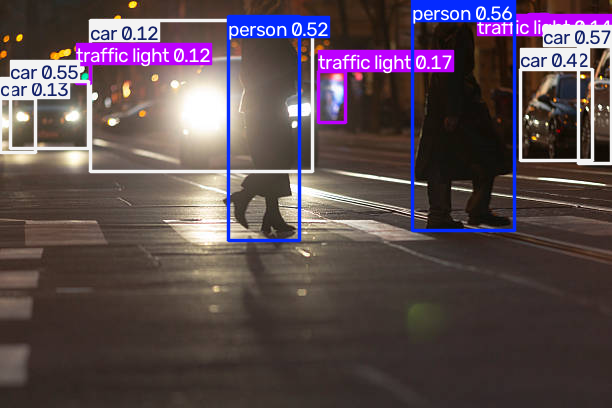


Mild CLAHE 1.5
Total detections: 11
car 0.73
car 0.659
person 0.629
person 0.558
car 0.526
traffic light 0.219
car 0.192
car 0.144
car 0.143
traffic light 0.138
car 0.104


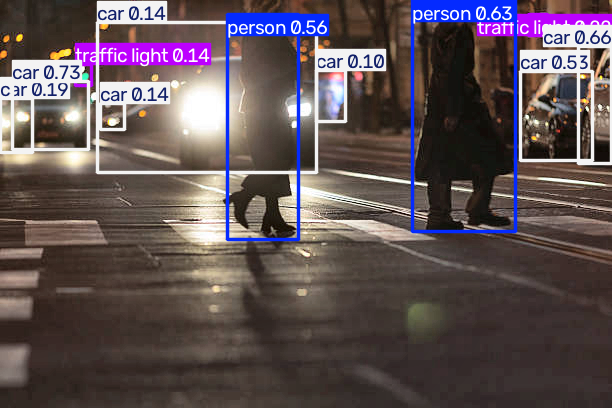


CLAHE 2.0
Total detections: 12
car 0.747
car 0.647
person 0.632
person 0.555
car 0.543
traffic light 0.236
car 0.192
car 0.173
car 0.141
traffic light 0.133
car 0.129
car 0.11


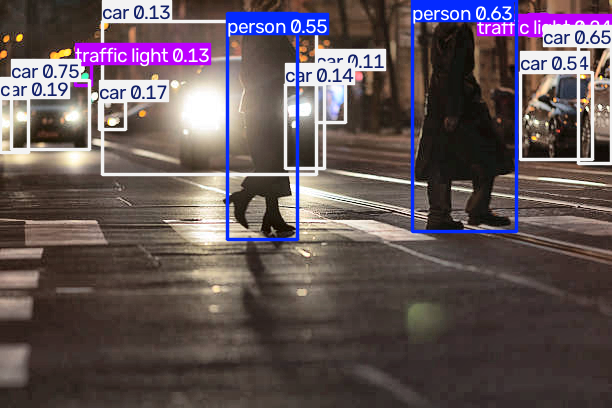

In [34]:

import cv2
import numpy as np
from PIL import Image
from IPython.display import display

def enhance_clahe(image, clip_limit):
    rgb = np.array(image.convert("RGB"))
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=(8, 8)
    )

    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    return Image.fromarray(enhanced)

experiments = [
    ("Original", night_image),
    ("Mild CLAHE 1.5", enhance_clahe(night_image, 1.5)),
    ("CLAHE 2.0", enhance_clahe(night_image, 2.0))
]

for name, image in experiments:
    result = model.predict(
        source=image,
        imgsz=416,
        conf=0.10,
        iou=0.30,
        verbose=False
    )[0]

    print(f"\n{name}")
    print(f"Total detections: {len(result.boxes)}")

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(
            model.names[class_id],
            round(confidence, 3)
        )

    display(Image.fromarray(result.plot()[:, :, ::-1]))
